<a href="https://colab.research.google.com/github/emilianomtz0189/credit-risk-scorecard/blob/main/notebooks/07_perdida_esperada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 · Pérdida esperada y propuesta de puntos de corte

**Objetivo:** traducir el scorecard a dinero y a decisiones: cuánto se espera perder por banda de puntaje y a partir de qué puntaje conviene **aprobar**, **revisar** o **rechazar** una solicitud.

## Conceptos

### Pérdida esperada (EL, *Expected Loss*)

$$\text{EL} = \text{PD} \times \text{LGD} \times \text{EAD}$$

| Componente | Pregunta que responde |
|---|---|
| **PD** (*Probability of Default*) | ¿Qué probabilidad hay de que el cliente no pague? La da el scorecard. |
| **LGD** (*Loss Given Default*) | Si no paga, ¿qué % de lo que debe se pierde, después de cobranza y recuperaciones? |
| **EAD** (*Exposure at Default*) | ¿Cuánto debe el cliente en el momento en que deja de pagar? |

**Ejemplo ilustrativo:** un crédito de $50,000 con PD de 5 % y LGD de 45 % tiene una pérdida esperada de 0.05 × 0.45 × 50,000 = **$1,125**. Es un costo "normal" del negocio: se cubre con la tasa de interés y con las reservas (en México, las *estimaciones preventivas para riesgos crediticios*). Las pérdidas mayores a lo esperado se cubren con capital.

### Punto de corte

Es el puntaje mínimo para aprobar. Se propone una estrategia de **tres zonas**, común en la industria:
- **Aprobación automática:** puntajes altos, riesgo bajo.
- **Revisión manual:** zona intermedia; un analista revisa información adicional (ingresos comprobables, garantías, historial con la institución).
- **Rechazo:** puntajes donde el cliente, en promedio, cuesta más de lo que deja.

### Supuestos (el dataset no trae montos ni recuperaciones)

*Give Me Some Credit* no incluye el monto del crédito, lo recuperado ni la tasa de interés. Por eso **LGD, EAD y margen son supuestos explícitos**, definidos en `src/perdida.py`, y al final se hace un **análisis de sensibilidad** para ver cuánto cambia la recomendación si cambian.

| Supuesto | Valor | Justificación |
|---|---|---|
| EAD por cliente | $50,000 | Crédito personal hipotético, igual para todos. Así la pérdida esperada es proporcional a la PD. |
| LGD | 45 % | Valor de referencia de Basilea para deuda sin garantía (enfoque básico). En crédito al consumo puede ser mayor; se evalúa en la sensibilidad. |
| Margen | 15 % de la EAD | Ingreso neto (intereses menos costo de fondeo y operación) de un cliente que paga, en el horizonte de 2 años. |

Todo se mide en el **mismo horizonte de 2 años** con que se definió a un cliente malo.

## Entorno

In [1]:
import os
import sys
from pathlib import Path

USUARIO_GITHUB = "emilianomtz0189"
NOMBRE_REPO = "credit-risk-scorecard"
CARPETA_DRIVE = Path("/content/drive/MyDrive/credit-risk-scorecard")  # Donde está cs-training.csv

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    ruta_repo = Path("/content") / NOMBRE_REPO
    if not ruta_repo.exists():
        !git clone -q https://github.com/{USUARIO_GITHUB}/{NOMBRE_REPO}.git {ruta_repo}
    else:
        !git -C {ruta_repo} pull -q
    os.chdir(ruta_repo)
elif Path.cwd().name == "notebooks":
    os.chdir("..")

sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

Mounted at /content/drive
Directorio de trabajo: /content/credit-risk-scorecard


In [2]:
!pip install -q -r requirements.txt

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import config
from src.datos import copiar_datos_crudos
from src.limpieza import obtener_datos_limpios
from src.perdida import (
    EAD_POR_CLIENTE,
    LGD,
    MARGEN,
    asignar_banda,
    calibrar_pd_por_banda,
    comparar_escenarios,
    corte_por_utilidad,
    evaluar_zonas,
    graficar_perdida_por_banda,
    pd_equilibrio,
    puntaje_ks,
    sensibilidad,
    tabla_perdida_esperada,
)
from src.scorecard import construir_scorecard, pd_desde_puntaje

config.fijar_semilla()
config.crear_carpetas()
pd.set_option("display.float_format", "{:,.4f}".format)

In [4]:
copiar_datos_crudos(CARPETA_DRIVE)
train, test = obtener_datos_limpios()
Y = config.COLUMNA_OBJETIVO

scorecard = construir_scorecard()
puntaje_train = scorecard["puntaje_train"]["puntaje"]
puntaje_test = scorecard["puntaje_test"]["puntaje"]

print(f"Supuestos: EAD = ${EAD_POR_CLIENTE:,} | LGD = {LGD:.0%} | Margen = {MARGEN:.0%}")

Copiado cs-training.csv a data/raw/cs-training.csv
Supuestos: EAD = $50,000 | LGD = 45% | Margen = 15%


## 1. PD calibrada por banda de puntaje

En la etapa 4 vimos que el scorecard **ordena** muy bien a los clientes, pero su PD exacta exageraba el riesgo de los mejores clientes. Para calcular dinero se necesita una PD precisa, así que se **calibra**: la PD de cada banda de puntaje es la tasa de malos observada en **entrenamiento**. Después se comprueba en **prueba** que la tasa real se parece a la calibrada.

In [5]:
calibracion = calibrar_pd_por_banda(puntaje_train, train[Y])

# Validación en prueba: tasa real por banda vs. PD calibrada en entrenamiento
validacion = (pd.DataFrame({"banda": asignar_banda(puntaje_test), "malo": test[Y]})
              .groupby("banda", observed=False)["malo"].agg(clientes_prueba="size", tasa_real_prueba="mean"))
validacion["pd_calibrada"] = calibracion["pd_calibrada"]
validacion["pd_original_scorecard"] = (pd.DataFrame({"banda": asignar_banda(puntaje_test),
                                                     "pd": pd_desde_puntaje(puntaje_test)})
                                       .groupby("banda", observed=False)["pd"].mean())

print("PD calibrada (entrenamiento)")
display(calibracion)
print("Validación en prueba")
display(validacion)

PD calibrada (entrenamiento)


,clientes,malos,pd_calibrada
banda,,,
< 500,3355,1760,0.5246
500–519,2840,1019,0.3588
520–539,4688,1060,0.2261
540–559,11072,1233,0.1114
560–579,16624,996,0.0599
580–599,23850,600,0.0252
600–619,37361,329,0.0088
620+,5210,21,0.0040


Validación en prueba


,clientes_prueba,tasa_real_prueba,pd_calibrada,pd_original_scorecard
banda,,,,
< 500,1404,0.5406,0.5246,0.6021
500–519,1169,0.3636,0.3588,0.3065
520–539,1983,0.2355,0.2261,0.1838
540–559,4768,0.1107,0.1114,0.0981
560–579,7122,0.0543,0.0599,0.0545
580–599,10374,0.0268,0.0252,0.0273
600–619,16007,0.0093,0.0088,0.0147
620+,2173,0.0069,0.0040,0.0092


## 2. Pérdida esperada por banda

Se aplica la PD calibrada a los clientes de prueba, como si fueran solicitudes nuevas. Las columnas acumuladas se leen de arriba hacia abajo: *"si apruebo desde la mejor banda hasta esta, ¿qué % de clientes apruebo y cuánta pérdida y utilidad espero?"*.

In [6]:
perdida = tabla_perdida_esperada(puntaje_test, calibracion["pd_calibrada"])

formato = {"pd": "{:.2%}", "pct_aprobacion_acum": "{:.2%}",
           **{c: "${:,.0f}" for c in ["exposicion", "perdida_esperada", "ingreso_esperado",
                                       "utilidad_esperada", "perdida_esperada_acum", "utilidad_esperada_acum"]}}
display(perdida.style.format(formato))

total_exposicion = perdida["exposicion"].sum()
total_perdida = perdida["perdida_esperada"].sum()
print(f"Cartera de prueba: exposición ${total_exposicion:,.0f} | pérdida esperada ${total_perdida:,.0f} "
      f"({total_perdida / total_exposicion:.2%} de la exposición)")

,clientes,pd,exposicion,perdida_esperada,ingreso_esperado,utilidad_esperada,pct_aprobacion_acum,perdida_esperada_acum,utilidad_esperada_acum
banda,,,,,,,,,
620+,2173,0.40%,"$108,650,000","$197,071","$16,231,810","$16,034,738",4.83%,"$197,071","$16,034,738"
600–619,16007,0.88%,"$800,350,000","$3,171,538","$118,995,321","$115,823,783",40.40%,"$3,368,609","$131,858,521"
580–599,10374,2.52%,"$518,700,000","$5,872,075","$75,847,642","$69,975,566",63.45%,"$9,240,685","$201,834,087"
560–579,7122,5.99%,"$356,100,000","$9,600,819","$50,214,727","$40,613,908",79.28%,"$18,841,504","$242,447,995"
540–559,4768,11.14%,"$238,400,000","$11,946,915","$31,777,695","$19,830,780",89.88%,"$30,788,419","$262,278,775"
520–539,1983,22.61%,"$99,150,000","$10,088,428","$11,509,691","$1,421,263",94.28%,"$40,876,847","$263,700,038"
500–519,1169,35.88%,"$58,450,000","$9,437,411","$5,621,696","$-3,815,715",96.88%,"$50,314,258","$259,884,323"
< 500,1404,52.46%,"$70,200,000","$16,571,803","$5,006,066","$-11,565,738",100.00%,"$66,886,061","$248,318,585"


Cartera de prueba: exposición $2,250,000,000 | pérdida esperada $66,886,061 (2.97% de la exposición)


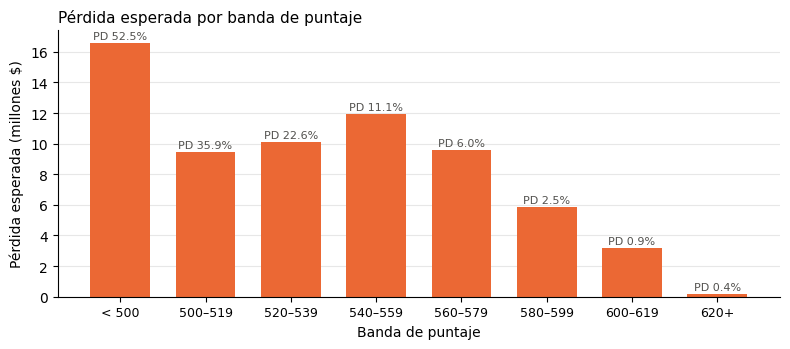

In [7]:
graficar_perdida_por_banda(perdida)
plt.show()

## 3. Puntos de corte

**Corte de rechazo (rentabilidad).** Un cliente es rentable si lo que deja cuando paga supera lo que se pierde cuando no paga:

$$(1 - \text{PD}) \times \text{margen} > \text{PD} \times \text{LGD} \quad\Rightarrow\quad \text{PD} < \frac{\text{margen}}{\text{margen} + \text{LGD}}$$

Las bandas con PD mayor a ese límite tienen utilidad esperada negativa y se rechazan.

**Corte de aprobación automática (KS).** Se usa el puntaje donde el scorecard alcanza su KS en **entrenamiento**: el punto de máxima separación entre buenos y malos. Arriba de él se aprueba sin revisión; entre ambos cortes, revisión manual.

In [8]:
limite_pd = pd_equilibrio()
corte_rechazo = corte_por_utilidad(calibracion["pd_calibrada"])
corte_aprobacion = puntaje_ks(puntaje_train, train[Y]) + 1   # Se aprueba por arriba del puntaje del KS

print(f"PD de equilibrio: {MARGEN:.0%} / ({MARGEN:.0%} + {LGD:.0%}) = {limite_pd:.2%}")
print(f"Corte de rechazo: puntaje < {corte_rechazo:.0f}")
print(f"Corte de aprobación automática (KS en entrenamiento): puntaje ≥ {corte_aprobacion:.0f}")

PD de equilibrio: 15% / (15% + 45%) = 25.00%
Corte de rechazo: puntaje < 520
Corte de aprobación automática (KS en entrenamiento): puntaje ≥ 568


## 4. Resultado de la estrategia en prueba (con los resultados reales)

Ahora sí se usa lo que realmente pasó con los clientes de prueba: cuántos fueron malos en cada zona y cuánto se habría ganado o perdido.

In [9]:
zonas = evaluar_zonas(puntaje_test, test[Y], corte_rechazo, corte_aprobacion)
formato_zonas = {"pct_clientes": "{:.2%}", "tasa_malos": "{:.2%}", "pct_malos_total": "{:.2%}",
                 "perdida": "${:,.0f}", "ingreso": "${:,.0f}", "utilidad": "${:,.0f}"}
zonas.style.format(formato_zonas)

,clientes,malos,pct_clientes,tasa_malos,pct_malos_total,perdida,ingreso,utilidad
zona,,,,,,,,
Aprobación automática,33076,652,73.50%,1.97%,21.68%,"$14,670,000","$243,180,000","$228,510,000"
Revisión manual,9351,1172,20.78%,12.53%,38.96%,"$26,370,000","$61,342,500","$34,972,500"
Rechazo,2573,1184,5.72%,46.02%,39.36%,"$26,640,000","$10,417,500","$-16,222,500"


In [10]:
escenarios = comparar_escenarios(zonas)
escenarios.style.format({"pct_aprobados": "{:.2%}", "tasa_malos_aprobados": "{:.2%}",
                         "perdida": "${:,.0f}", "utilidad": "${:,.0f}"})

,pct_aprobados,tasa_malos_aprobados,perdida,utilidad
escenario,,,,
Aprobar a todos,100.00%,6.68%,"$67,680,000","$247,260,000"
Aprobación automática + revisión,94.28%,4.30%,"$41,040,000","$263,482,500"
Solo aprobación automática,73.50%,1.97%,"$14,670,000","$228,510,000"


## 5. Sensibilidad a los supuestos

¿Qué pasa con el corte de rechazo si la LGD o el margen son distintos? Si la recomendación cambia mucho, los supuestos deben validarse con datos reales de la institución antes de implementarla.

In [11]:
tabla_sensibilidad = sensibilidad(calibracion["pd_calibrada"], puntaje_test,
                                  lgds=[0.35, 0.45, 0.65, 0.85], margenes=[0.10, 0.15, 0.25])
tabla_sensibilidad.style.format({"lgd": "{:.0%}", "margen": "{:.0%}", "pd_equilibrio": "{:.2%}",
                                 "corte_rechazo": "{:.0f}", "pct_aprobacion": "{:.2%}"})

,lgd,margen,pd_equilibrio,corte_rechazo,pct_aprobacion
0,35%,10%,22.22%,540,89.88%
1,35%,15%,30.00%,520,94.28%
2,35%,25%,41.67%,500,96.88%
3,45%,10%,18.18%,540,89.88%
4,45%,15%,25.00%,520,94.28%
5,45%,25%,35.71%,520,94.28%
6,65%,10%,13.33%,540,89.88%
7,65%,15%,18.75%,540,89.88%
8,65%,25%,27.78%,520,94.28%
9,85%,10%,10.53%,560,79.28%


## Hallazgos de la etapa

- **Calibración:** la PD calibrada por banda se acerca mucho a la tasa real de prueba (< 500 puntos: 52.46 % vs. 54.06 %; 600–619: 0.88 % vs. 0.93 %), mientras que la PD original del scorecard se alejaba más en los extremos (60.21 % y 1.47 %, respectivamente). La PD calibrada es la que se usa para calcular dinero.
- **Pérdida esperada de la cartera de prueba:** $66,886,061 sobre una exposición de $2,250,000,000, es decir, 2.97 % (consistente con 6.68 % de malos × 45 % de LGD).
- **Concentración de la pérdida:** las bandas menores a 520 puntos son solo el 5.72 % de los clientes, pero concentran $26,009,214 de pérdida esperada (39 % del total) y tienen utilidad esperada negativa.
- **Puntos de corte propuestos:** con margen de 15 % y LGD de 45 %, la PD de equilibrio es 25 %. **Rechazo** debajo de 520 puntos (5.72 % de las solicitudes), **revisión manual** de 520 a 567 (20.78 %) y **aprobación automática** desde 568 (73.50 %), el puntaje del KS en entrenamiento.
- **Resultado real en prueba por zona:** tasa de malos de 1.97 % en aprobación automática, 12.53 % en revisión manual y 46.02 % en rechazo. Rechazando solo al 5.72 % de los clientes se evita el 39.36 % de todos los incumplimientos.
- **Comparación de escenarios (resultados reales de prueba):** aprobar a todos deja una utilidad de $247,260,000 con pérdida de $67,680,000. Aprobar automática + revisión (94.28 % de aprobación) reduce la pérdida a $41,040,000 (−39 %), baja la tasa de malos de 6.68 % a 4.30 % y sube la utilidad a $263,482,500 (+$16,222,500). Aprobar solo la zona automática deja menos utilidad ($228,510,000) porque la zona de revisión es rentable en promedio: debe revisarse para depurarla, no rechazarse completa.
- **Sensibilidad:** con LGD entre 35 % y 85 % y margen entre 10 % y 25 %, el corte de rechazo queda entre 500 y 560 puntos, y en 9 de los 12 escenarios entre 520 y 540. La recomendación es robusta, pero los montos absolutos dependen de los supuestos y deben validarse con datos reales de la institución (monto, tasa y recuperación).

## Resumen de la etapa

- Se calibró la PD por banda de puntaje con entrenamiento y se validó en prueba.
- Se calculó la pérdida esperada (PD × LGD × EAD) por banda, con supuestos explícitos de LGD, EAD y margen.
- Se propuso una estrategia de tres zonas: rechazo por rentabilidad, revisión manual y aprobación automática desde el punto de máximo KS.
- Se evaluó la estrategia con los resultados reales de prueba y se analizó su sensibilidad a los supuestos.

**Siguiente paso:** README final con resumen de negocio y publicación del proyecto.